# Task 1B: Analytical Questions (Part 1)
**Group assignment:** Working with Time Series Data
**Author:** David NGARAMBE (Member 1: exploratory analysis and preprocessing)

This notebook builds on `01_eda_preprocessing.ipynb`. It (1) creates the lag, moving-average and calendar features that the group agreed on, and (2) answers the first three analytical questions. Part 2 (`03_analytical_questions_part2.ipynb`) answers the remaining questions.

| # | Analytical question | Technique |
|---|---|---|
| Q1 | Does electricity demand show a long-term increasing or decreasing trend? | 365-day moving average, annual means, linear regression |
| Q2 | How does demand change over the day and the week? | hour-of-day and day-of-week profiles |
| Q3 | How does demand change through the year, and does it follow temperature? | monthly profile, month-by-hour heatmap |

## 1. Setup

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

# Consistent colours across the whole project: blue = demand, orange = temperature / weekend, grey = context
BLUE, ORANGE, GREY, DARK = "#2a78d6", "#eb6834", "#9a9a96", "#333333"

plt.rcParams.update({
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.25, "grid.linewidth": 0.6,
    "lines.linewidth": 1.8, "axes.titleweight": "bold", "axes.titlesize": 12,
    "axes.titlelocation": "left", "figure.dpi": 100,
})
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)

PROCESSED_DIR = Path("../data/processed")

## 2. Feature engineering (agreed with the group)

All features are defined so that **only information available before the hour being predicted is used**. This prevents data leakage when teammate 2 trains the model.

| Feature | Definition |
|---|---|
| `hour` | hour of day (0 to 23) |
| `day_of_week` | 0 = Monday ... 6 = Sunday |
| `month` | 1 to 12 |
| `is_weekend` | 1 if Saturday or Sunday, else 0 |
| `lag_1`, `lag_24`, `lag_168` | demand 1 hour, 24 hours (one day) and 168 hours (one week) earlier |
| `rolling_mean_24`, `rolling_mean_168` | mean of the previous 24 / 168 hours, **excluding the current hour** |

In [2]:
df = pd.read_csv(PROCESSED_DIR / "pjme_clean.csv", parse_dates=["Datetime"]).set_index("Datetime")

# The index must be a perfect hourly sequence, otherwise shift(24) would not mean "24 hours ago"
assert df.index.is_monotonic_increasing and df.index.is_unique
assert (df.index.to_series().diff().dropna() == pd.Timedelta(hours=1)).all()

feat = df.copy()

# calendar features
feat["hour"] = feat.index.hour
feat["day_of_week"] = feat.index.dayofweek
feat["month"] = feat.index.month
feat["is_weekend"] = (feat["day_of_week"] >= 5).astype(int)

# lag features
for k in (1, 24, 168):
    feat[f"lag_{k}"] = feat["PJME_MW"].shift(k)

# moving averages of the PREVIOUS n hours: shift(1) first so the current hour is excluded
for n in (24, 168):
    feat[f"rolling_mean_{n}"] = feat["PJME_MW"].shift(1).rolling(window=n).mean()

feat.iloc[165:172][["PJME_MW", "lag_1", "lag_24", "lag_168", "rolling_mean_24", "rolling_mean_168"]]

,PJME_MW,lag_1,lag_24,lag_168,rolling_mean_24,rolling_mean_168
Datetime,,,,,,
2002-01-07 22:00:00,"35,997.00","37,777.00","32,731.00",NaN,"33,075.54",NaN
2002-01-07 23:00:00,"33,579.00","35,997.00","30,646.00",NaN,"33,211.62",NaN
2002-01-08 00:00:00,"31,187.00","33,579.00","28,337.00",NaN,"33,333.83",NaN
2002-01-08 01:00:00,"29,445.00","31,187.00","26,862.00","30,393.00","33,452.58","32,519.51"
2002-01-08 02:00:00,"28,670.00","29,445.00","25,976.00","29,265.00","33,560.21","32,513.87"
2002-01-08 03:00:00,"28,375.00","28,670.00","25,641.00","28,357.00","33,672.46","32,510.33"
2002-01-08 04:00:00,"28,542.00","28,375.00","25,666.00","27,899.00","33,786.38","32,510.43"


In [3]:
# Verification: rebuild one row by hand and compare with the feature columns
t = feat.index[1000]
previous_24 = df["PJME_MW"].loc[t - pd.Timedelta(hours=24): t - pd.Timedelta(hours=1)]
assert len(previous_24) == 24
assert np.isclose(previous_24.mean(), feat.loc[t, "rolling_mean_24"])
assert feat.loc[t, "lag_24"] == df["PJME_MW"].loc[t - pd.Timedelta(hours=24)]
assert feat.loc[t, "lag_168"] == df["PJME_MW"].loc[t - pd.Timedelta(hours=168)]
print("Feature checks passed for", t)
print("NaN per feature:", feat.isna().sum()[lambda s: s > 0].to_dict())

Feature checks passed for 2002-02-11 17:00:00
NaN per feature: {'lag_1': 1, 'lag_24': 24, 'lag_168': 168, 'rolling_mean_24': 24, 'rolling_mean_168': 168}


In [4]:
# The first 168 hours have no full history, so those rows cannot be used for modelling
model_ready = feat.dropna().reset_index()
cols = ["Datetime", "PJME_MW", "temperature_c", "hour", "day_of_week", "month", "is_weekend",
        "lag_1", "lag_24", "lag_168", "rolling_mean_24", "rolling_mean_168", "was_imputed"]
model_ready = model_ready[cols]
model_ready.to_csv(PROCESSED_DIR / "pjme_features.csv", index=False)
print("Saved", PROCESSED_DIR / "pjme_features.csv", model_ready.shape)
model_ready.head(3)

Saved ../data/processed/pjme_features.csv (145224, 13)


,Datetime,PJME_MW,temperature_c,hour,day_of_week,month,is_weekend,lag_1,lag_24,lag_168,rolling_mean_24,rolling_mean_168,was_imputed
0,2002-01-08 01:00:00,"29,445.00",-4.70,1,1,1,0,"31,187.00","26,862.00","30,393.00","33,452.58","32,519.51",False
1,2002-01-08 02:00:00,"28,670.00",-5.60,2,1,1,0,"29,445.00","25,976.00","29,265.00","33,560.21","32,513.87",False
2,2002-01-08 03:00:00,"28,375.00",-5.20,3,1,1,0,"28,670.00","25,641.00","28,357.00","33,672.46","32,510.33",False


**Result:** the feature table has **145,224 rows**. The first 168 hours (one week) are dropped because `lag_168` and `rolling_mean_168` need a full week of history. Verification cells confirm that one row rebuilt by hand matches the vectorised columns, so the features look back only and cannot leak the value being predicted.

## Q1. Does electricity demand have a long-term trend?

**Approach:** hourly data is dominated by daily and seasonal swings, so a trend is invisible unless those cycles are averaged out. A **365-day moving average** (8,760 hours) removes a full seasonal cycle. Then the **annual means** are tested with a linear regression. 2018 is excluded from the regression because the data stops on 3 August, and a January-to-August average is not comparable with a full year.

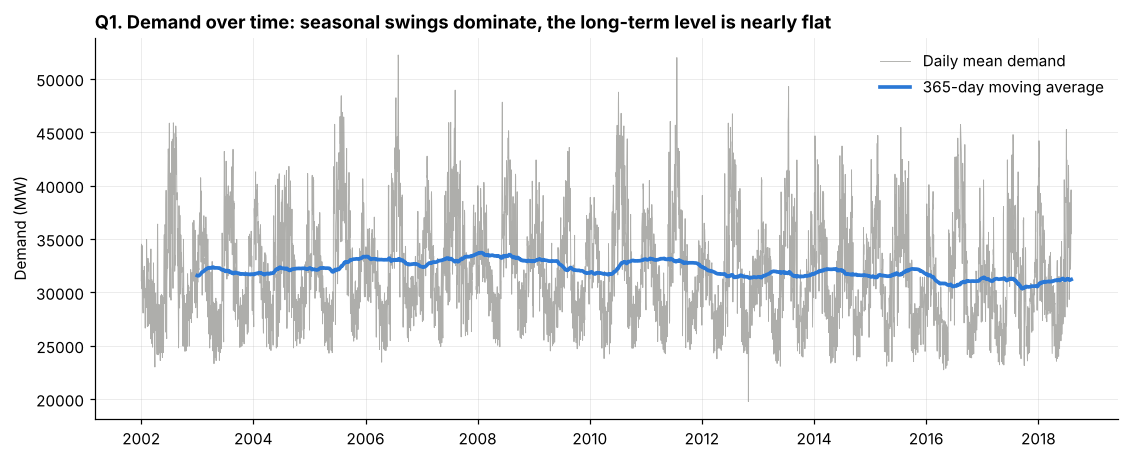

In [5]:
analysis = feat.copy()
analysis["year"] = analysis.index.year

daily = analysis["PJME_MW"].resample("D").mean()
ma_365 = analysis["PJME_MW"].rolling(window=24 * 365).mean()   # 365-day moving average

fig, ax = plt.subplots(figsize=(12, 4.5))
ax.plot(daily.index, daily, color=GREY, lw=0.6, alpha=0.8, label="Daily mean demand")
ax.plot(ma_365.index, ma_365, color=BLUE, lw=2.4, label="365-day moving average")
ax.set(title="Q1. Demand over time: seasonal swings dominate, the long-term level is nearly flat",
       ylabel="Demand (MW)", xlabel="")
ax.legend(frameon=False, loc="upper right")
plt.show()

Trend: -83.8 MW per year  (R² = 0.241, p-value = 0.054)
Average 2002-2005: 32,209 MW
Average 2014-2017: 31,299 MW
Correlation of annual demand with annual mean temperature: -0.01


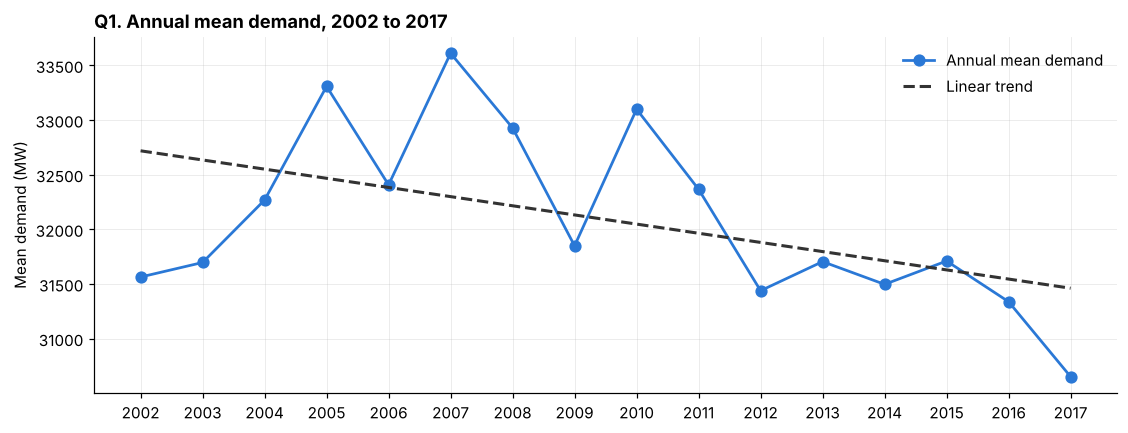

,demand,temperature,hours
year,,,
2002,"31,563.70",13.30,8759
2003,"31,696.70",11.60,8760
2004,"32,268.20",12.30,8784
2005,"33,308.40",12.50,8760
2006,"32,407.10",13.50,8760
2007,"33,611.40",13.00,8760
2008,"32,927.90",13.00,8784
2009,"31,849.30",12.20,8760
2010,"33,099.40",13.40,8760


In [6]:
annual = analysis.groupby("year").agg(demand=("PJME_MW", "mean"), temperature=("temperature_c", "mean"),
                                     hours=("PJME_MW", "size"))
full_years = annual[annual["hours"] >= 8700]          # 2002 to 2017 (2018 is partial)

fit = stats.linregress(full_years.index, full_years["demand"])
print(f"Trend: {fit.slope:+,.1f} MW per year  (R² = {fit.rvalue**2:.3f}, p-value = {fit.pvalue:.3f})")
print(f"Average 2002-2005: {full_years.loc[2002:2005, 'demand'].mean():,.0f} MW")
print(f"Average 2014-2017: {full_years.loc[2014:2017, 'demand'].mean():,.0f} MW")
print(f"Correlation of annual demand with annual mean temperature: "
      f"{full_years['demand'].corr(full_years['temperature']):.2f}")

fig, ax = plt.subplots(figsize=(12, 4.2))
ax.plot(full_years.index, full_years["demand"], color=BLUE, marker="o", ms=7, label="Annual mean demand")
ax.plot(full_years.index, fit.intercept + fit.slope * full_years.index, color=DARK, lw=2, ls="--",
        label="Linear trend")
ax.set(title="Q1. Annual mean demand, 2002 to 2017", ylabel="Mean demand (MW)")
ax.set_xticks(full_years.index)
ax.legend(frameon=False, loc="upper right")
plt.show()
full_years.round(1)

**Interpretation**
- The daily means swing between roughly 20,000 and 52,000 MW within every year, while the 365-day moving average stays inside a narrow band of about **30,500 to 33,700 MW**. **Seasonal and daily cycles dominate; the long-term level is nearly flat.**
- There is a small rise from 2002 to its peak around **2007** (annual mean 33,611 MW), then a gradual decline to **30,652 MW in 2017**.
- The fitted trend is **-84 MW per year** (about -0.26% per year). Average demand fell from 32,209 MW in 2002-2005 to 31,299 MW in 2014-2017, a drop of **2.8%**. However, with R² = 0.24 and **p = 0.054**, the decline is only borderline and **not statistically significant at the usual 5% level**, so the safest conclusion is a *slight, uncertain downward drift*.
- Annual mean temperature is essentially unrelated to annual demand (correlation -0.01), so warmer or colder years on average do not explain the changes. Possible causes such as energy efficiency or the 2008-2009 recession were not tested here.
- **Implication for modelling:** the level is stable enough that no trend removal is needed. Lag features (`lag_24`, `lag_168`) already carry the recent level into each prediction, and the train/test split should be chronological.

## Q2. How does demand change over the day and across the week?

**Approach:** average demand for each hour of the day, separately for weekdays and weekends, then for each day of the week. This shows the human routine that drives demand and tells the model which calendar features matter.

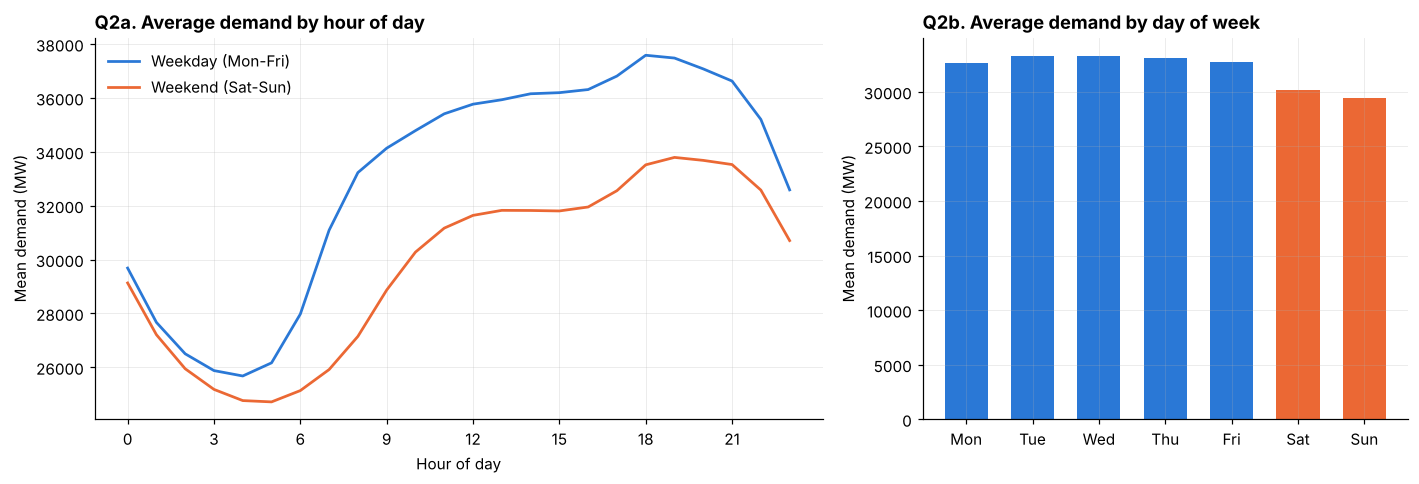

In [7]:
profile = analysis.groupby(["is_weekend", "hour"])["PJME_MW"].mean().unstack(0)
profile.columns = ["Weekday", "Weekend"]

dow_names = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
by_dow = analysis.groupby("day_of_week")["PJME_MW"].mean()

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), gridspec_kw={"width_ratios": [1.5, 1]})

ax = axes[0]
ax.plot(profile.index, profile["Weekday"], color=BLUE, label="Weekday (Mon-Fri)")
ax.plot(profile.index, profile["Weekend"], color=ORANGE, label="Weekend (Sat-Sun)")
ax.set(title="Q2a. Average demand by hour of day", xlabel="Hour of day", ylabel="Mean demand (MW)")
ax.set_xticks(range(0, 24, 3))
ax.legend(frameon=False)

ax = axes[1]
colors = [BLUE] * 5 + [ORANGE] * 2
ax.bar(dow_names, by_dow.values, color=colors, width=0.65)
ax.set(title="Q2b. Average demand by day of week", ylabel="Mean demand (MW)")
plt.tight_layout()
plt.show()

In [8]:
print("Weekday: lowest hour =", profile["Weekday"].idxmin(), f"({profile['Weekday'].min():,.0f} MW),",
      "highest hour =", profile["Weekday"].idxmax(), f"({profile['Weekday'].max():,.0f} MW)")
print("Weekend: lowest hour =", profile["Weekend"].idxmin(), f"({profile['Weekend'].min():,.0f} MW),",
      "highest hour =", profile["Weekend"].idxmax(), f"({profile['Weekend'].max():,.0f} MW)")
wk, we = by_dow.iloc[:5].mean(), by_dow.iloc[5:].mean()
print(f"Mean weekday {wk:,.0f} MW vs mean weekend {we:,.0f} MW  ->  weekend is {100 * (we / wk - 1):.1f}%")
pd.DataFrame({"day": dow_names, "mean_demand_MW": by_dow.values})

Weekday: lowest hour = 4 (25,676 MW), highest hour = 18 (37,584 MW)
Weekend: lowest hour = 5 (24,714 MW), highest hour = 19 (33,791 MW)
Mean weekday 32,996 MW vs mean weekend 29,784 MW  ->  weekend is -9.7%


,day,mean_demand_MW
0,Mon,"32,672.03"
1,Tue,"33,272.27"
2,Wed,"33,261.50"
3,Thu,"33,085.86"
4,Fri,"32,688.23"
5,Sat,"30,162.88"
6,Sun,"29,405.85"


**Interpretation**
- **Daily shape:** demand is lowest in the early morning (weekdays at 04:00 with 25,676 MW) and climbs sharply between 05:00 and 09:00 as people wake and businesses open. It then stays high through the afternoon and reaches its **maximum in the evening (18:00 to 19:00, 37,584 MW on weekdays)** before falling quickly after 21:00.
- **Weekdays versus weekends:** the weekend curve has the same shape but sits about 1,000 MW lower at night and about 4,000 MW lower during the day, and it rises later and more gently. Its peak is only 33,791 MW (19:00).
- **Day of week:** Tuesday to Thursday are the highest (about 33,000 MW). Monday and Friday are slightly lower, and **Saturday (30,163 MW) and Sunday (29,406 MW) are the lowest**. The average weekend day is **9.7% below** the average weekday.
- **Implication for modelling:** `hour` and `is_weekend` carry strong, regular signal, and `lag_24` (same hour yesterday) and `lag_168` (same hour last week) should be informative because the routine repeats daily and weekly.

## Q3. How does demand change through the year, and does it follow temperature?

**Approach:** compare average demand and average temperature for each calendar month, then use a month-by-hour heatmap to see how the daily shape changes between seasons. Demand and temperature are plotted on **separate charts** (not on two y-axes) so neither scale distorts the other.

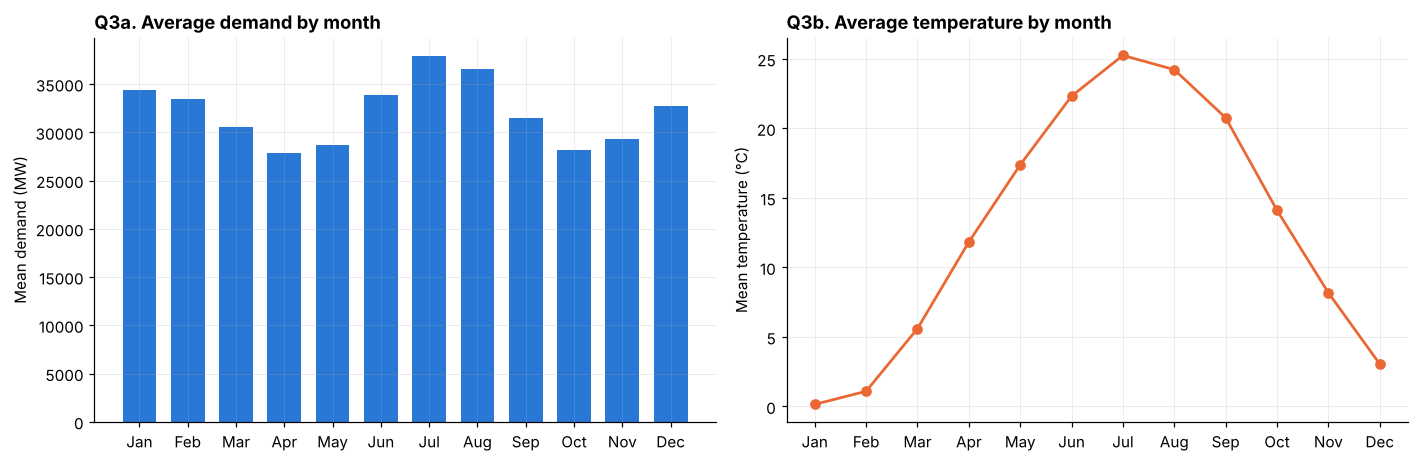

month,Jan,Feb,Mar,Apr,May,Jun,Jul,Aug,Sep,Oct,Nov,Dec
demand,"34,343.20","33,435.00","30,510.00","27,861.40","28,695.40","33,811.80","37,882.00","36,596.00","31,484.10","28,117.00","29,327.70","32,676.50"
temperature,0.20,1.10,5.60,11.80,17.40,22.30,25.20,24.20,20.80,14.10,8.20,3.10


In [9]:
month_names = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
monthly = analysis.groupby("month").agg(demand=("PJME_MW", "mean"), temperature=("temperature_c", "mean"))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.3))
axes[0].bar(month_names, monthly["demand"], color=BLUE, width=0.7)
axes[0].set(title="Q3a. Average demand by month", ylabel="Mean demand (MW)")
axes[1].plot(month_names, monthly["temperature"], color=ORANGE, marker="o", ms=6)
axes[1].set(title="Q3b. Average temperature by month", ylabel="Mean temperature (°C)")
plt.tight_layout()
plt.show()
monthly.assign(month=month_names).set_index("month").round(1).T

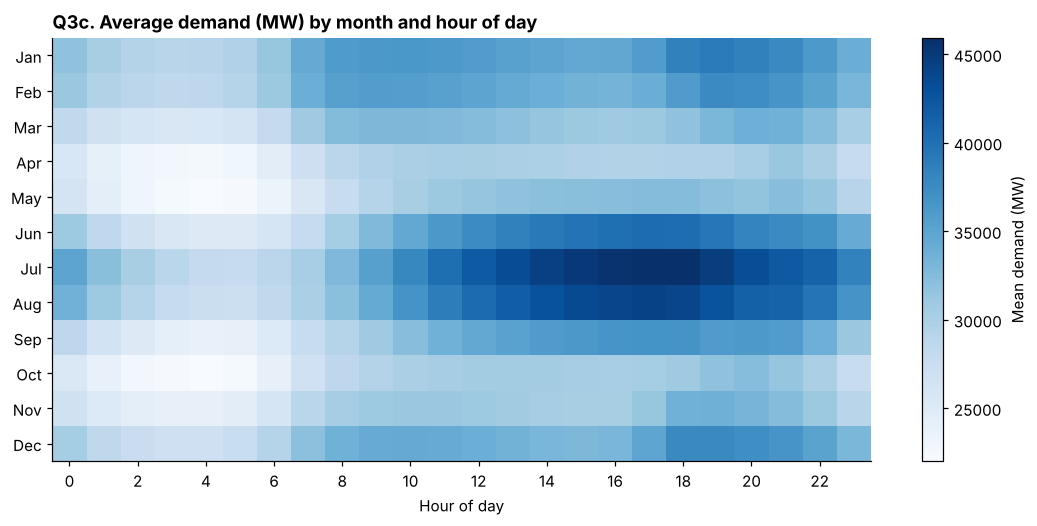

In [10]:
heat = analysis.pivot_table(index="month", columns="hour", values="PJME_MW", aggfunc="mean")
fig, ax = plt.subplots(figsize=(12, 5))
im = ax.imshow(heat.values, aspect="auto", cmap="Blues")
ax.set_xticks(range(0, 24, 2)); ax.set_xticklabels(range(0, 24, 2))
ax.set_yticks(range(12)); ax.set_yticklabels(month_names)
ax.grid(False)
ax.set(title="Q3c. Average demand (MW) by month and hour of day", xlabel="Hour of day")
fig.colorbar(im, ax=ax, label="Mean demand (MW)")
plt.show()

In [11]:
r_monthly = monthly["demand"].corr(monthly["temperature"])
print(f"Highest-demand month: {month_names[monthly['demand'].idxmax() - 1]} ({monthly['demand'].max():,.0f} MW)")
print(f"Lowest-demand month:  {month_names[monthly['demand'].idxmin() - 1]} ({monthly['demand'].min():,.0f} MW)")
print(f"Second peak (winter): Jan {monthly.loc[1, 'demand']:,.0f} MW, Feb {monthly.loc[2, 'demand']:,.0f} MW")
print(f"Linear correlation, monthly demand vs monthly temperature: {r_monthly:.2f}")
print("Peak hour by season:",
      {m: int(heat.loc[m].idxmax()) for m in (1, 4, 7, 10)}, "(month: hour)")

Highest-demand month: Jul (37,882 MW)
Lowest-demand month:  Apr (27,861 MW)
Second peak (winter): Jan 34,343 MW, Feb 33,435 MW
Linear correlation, monthly demand vs monthly temperature: 0.28
Peak hour by season: {1: 19, 4: 21, 7: 17, 10: 20} (month: hour)


**Interpretation**
- **Two peaks per year:** demand is highest in **July (37,882 MW)** and August, and has a second, smaller peak in **January (34,343 MW)** and February. It is lowest in **April (27,861 MW)** and also low in May and October, the mild months.
- Temperature rises from 0.2 °C in January to 25.2 °C in July, yet demand is high at *both* extremes. That is why the straight-line correlation between monthly demand and monthly temperature is only **0.28**: demand rises with heat (air conditioning) **and** with cold (heating), a U-shaped relationship that Part 2 tests directly.
- **The heatmap shows how the daily pattern changes by season.** In summer (June to August) demand peaks in the **afternoon (about 14:00 to 18:00)**, when it is hottest. In winter (December to February) there are **two bumps**, a morning one (about 08:00 to 09:00) and a stronger evening one (about 18:00 to 20:00), matching heating and lighting. Spring and autumn are the lowest and flattest.
- **Implication for modelling:** `month` and `hour` interact, because the same hour has different demand in different seasons, so tree-based or neural models, or interaction features, are likely to do better than a plain linear model on calendar features alone.

## Summary so far

Q1 to Q3 are answered with charts and interpretations. The features `lag_1`, `lag_24`, `lag_168`, `rolling_mean_24` and `rolling_mean_168` are saved in `data/processed/pjme_features.csv`. The next notebook uses them to answer the questions on temperature, lag effects and moving averages.